In [317]:
# Uber Ride Analysis
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv('My Uber Drives - 2016.csv')
df.head()

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
0,1/1/2016 21:11,1/1/2016 21:17,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain
1,1/2/2016 1:25,1/2/2016 1:37,Business,Fort Pierce,Fort Pierce,5.0,NaN
2,1/2/2016 20:25,1/2/2016 20:38,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies
3,1/5/2016 17:31,1/5/2016 17:45,Business,Fort Pierce,Fort Pierce,4.7,Meeting
4,1/6/2016 14:42,1/6/2016 15:49,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit


In [318]:
df.tail()

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
1151,12/31/2016 13:24,12/31/2016 13:42,Business,Kar?chi,Unknown Location,3.9,Temporary Site
1152,12/31/2016 15:03,12/31/2016 15:38,Business,Unknown Location,Unknown Location,16.2,Meeting
1153,12/31/2016 21:32,12/31/2016 21:50,Business,Katunayake,Gampaha,6.4,Temporary Site
1154,12/31/2016 22:08,12/31/2016 23:51,Business,Gampaha,Ilukwatta,48.2,Temporary Site
1155,Totals,NaN,NaN,NaN,NaN,12204.7,NaN


In [319]:
df.drop(1155, inplace=True)

In [320]:
df.tail()

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
1150,12/31/2016 1:07,12/31/2016 1:14,Business,Kar?chi,Kar?chi,0.7,Meeting
1151,12/31/2016 13:24,12/31/2016 13:42,Business,Kar?chi,Unknown Location,3.9,Temporary Site
1152,12/31/2016 15:03,12/31/2016 15:38,Business,Unknown Location,Unknown Location,16.2,Meeting
1153,12/31/2016 21:32,12/31/2016 21:50,Business,Katunayake,Gampaha,6.4,Temporary Site
1154,12/31/2016 22:08,12/31/2016 23:51,Business,Gampaha,Ilukwatta,48.2,Temporary Site


In [321]:
df['START_DATE'] = pd.to_datetime(df['START_DATE*'])
df['END_DATE'] = pd.to_datetime(df['END_DATE*'])

In [322]:
df.tail()

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*,START_DATE,END_DATE
1150,12/31/2016 1:07,12/31/2016 1:14,Business,Kar?chi,Kar?chi,0.7,Meeting,2016-12-31 01:07:00,2016-12-31 01:14:00
1151,12/31/2016 13:24,12/31/2016 13:42,Business,Kar?chi,Unknown Location,3.9,Temporary Site,2016-12-31 13:24:00,2016-12-31 13:42:00
1152,12/31/2016 15:03,12/31/2016 15:38,Business,Unknown Location,Unknown Location,16.2,Meeting,2016-12-31 15:03:00,2016-12-31 15:38:00
1153,12/31/2016 21:32,12/31/2016 21:50,Business,Katunayake,Gampaha,6.4,Temporary Site,2016-12-31 21:32:00,2016-12-31 21:50:00
1154,12/31/2016 22:08,12/31/2016 23:51,Business,Gampaha,Ilukwatta,48.2,Temporary Site,2016-12-31 22:08:00,2016-12-31 23:51:00


In [323]:
df['Hour'] = df['START_DATE'].dt.hour

In [324]:
df['Day_of_Week'] = df['START_DATE'].dt.day_name()

In [325]:
df['Month'] = df['START_DATE'].dt.month_name()

In [326]:
df['Ride_Duration'] = (df['END_DATE'] - df['START_DATE']).dt.total_seconds() / 60

In [327]:
print(df.isnull().sum())

START_DATE*        0
END_DATE*          0
CATEGORY*          0
START*             0
STOP*              0
MILES*             0
PURPOSE*         502
START_DATE         0
END_DATE           0
Hour               0
Day_of_Week        0
Month              0
Ride_Duration      0
dtype: int64


In [328]:
df.rename(columns={'PURPOSE*':'PURPOSE'},inplace=True)

In [329]:
print("\nDataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)


Dataset Shape: (1155, 13)

First 5 rows:
      START_DATE*       END_DATE* CATEGORY*       START*            STOP*  \
0  1/1/2016 21:11  1/1/2016 21:17  Business  Fort Pierce      Fort Pierce   
1   1/2/2016 1:25   1/2/2016 1:37  Business  Fort Pierce      Fort Pierce   
2  1/2/2016 20:25  1/2/2016 20:38  Business  Fort Pierce      Fort Pierce   
3  1/5/2016 17:31  1/5/2016 17:45  Business  Fort Pierce      Fort Pierce   
4  1/6/2016 14:42  1/6/2016 15:49  Business  Fort Pierce  West Palm Beach   

   MILES*          PURPOSE          START_DATE            END_DATE  Hour  \
0     5.1   Meal/Entertain 2016-01-01 21:11:00 2016-01-01 21:17:00    21   
1     5.0              NaN 2016-01-02 01:25:00 2016-01-02 01:37:00     1   
2     4.8  Errand/Supplies 2016-01-02 20:25:00 2016-01-02 20:38:00    20   
3     4.7          Meeting 2016-01-05 17:31:00 2016-01-05 17:45:00    17   
4    63.7   Customer Visit 2016-01-06 14:42:00 2016-01-06 15:49:00    14   

  Day_of_Week    Month  Ride_Duration 

In [330]:
total_rides = len(df)
print("Total Number of Rides:", total_rides)

Total Number of Rides: 1155


In [331]:
average_distance = df['MILES*'].mean()
print("Average Ride Distance: {:.2f} miles".format(average_distance))

Average Ride Distance: 10.57 miles


In [345]:
df.rename(columns={
    'CATEGORY*': 'Category',
    'START*': 'Start_Location',
    'STOP*': 'Stop_Location',
    'PURPOSE*': 'Purpose'
}, inplace=True)

In [ ]:
df.head()

In [346]:
df['PURPOSE'] = df['PURPOSE'].fillna('Unknown')

In [347]:
df.head()

,START_DATE*,END_DATE*,Category,Start_Location,Stop_Location,MILES*,PURPOSE,START_DATE,END_DATE,Hour,Day_of_Week,Month,Ride_Duration,Estimated_Fare,Peak_Hour_Count
0,1/1/2016 21:11,1/1/2016 21:17,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain,2016-01-01 21:11:00,2016-01-01 21:17:00,21,Friday,January,6.0,127.5,51
1,1/2/2016 1:25,1/2/2016 1:37,Business,Fort Pierce,Fort Pierce,5.0,Unknown,2016-01-02 01:25:00,2016-01-02 01:37:00,1,Saturday,January,12.0,125.0,5
2,1/2/2016 20:25,1/2/2016 20:38,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies,2016-01-02 20:25:00,2016-01-02 20:38:00,20,Saturday,January,13.0,120.0,71
3,1/5/2016 17:31,1/5/2016 17:45,Business,Fort Pierce,Fort Pierce,4.7,Meeting,2016-01-05 17:31:00,2016-01-05 17:45:00,17,Tuesday,January,14.0,117.5,95
4,1/6/2016 14:42,1/6/2016 15:49,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit,2016-01-06 14:42:00,2016-01-06 15:49:00,14,Wednesday,January,67.0,1592.5,89


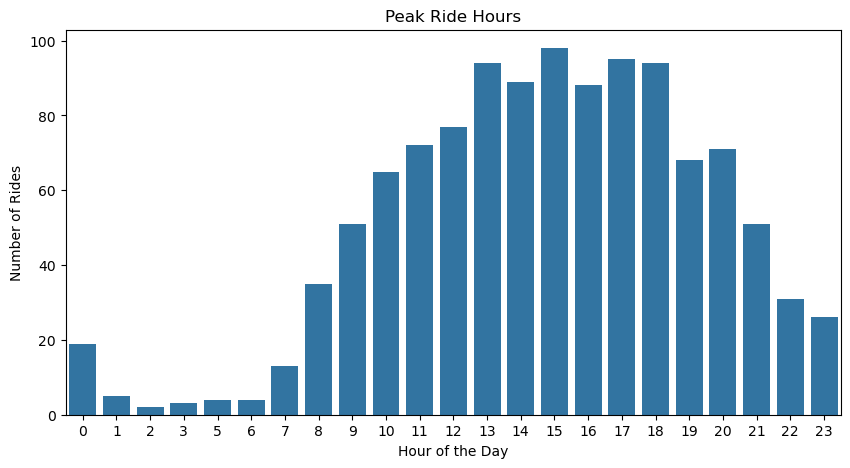

In [353]:
hour_count = df["Hour"].value_counts().sort_index().reset_index()
hour_count.columns = ["Hour", "Ride_Count"]

plt.figure(figsize=(10,5))
sns.barplot(data=hour_count, x="Hour", y="Ride_Count")

plt.title("Peak Ride Hours")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Rides")
plt.show()

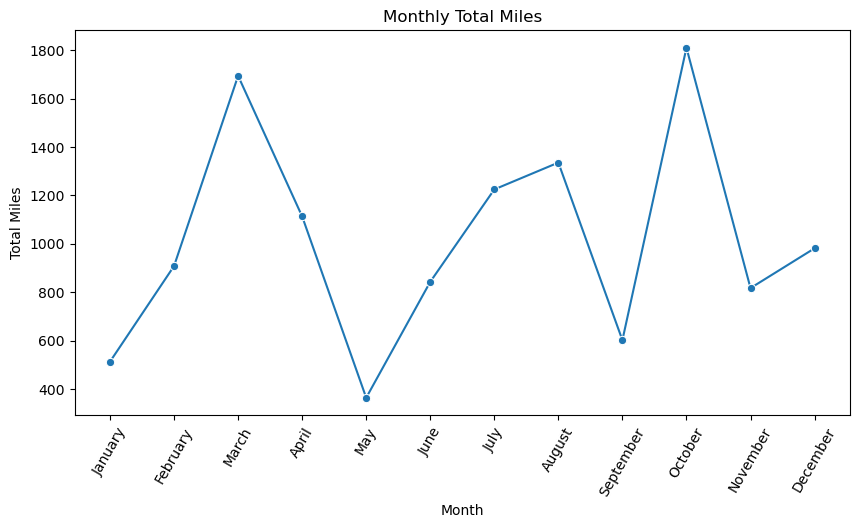

In [365]:
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

df['Month'] = pd.Categorical(df['Month'],
                             categories=month_order,
                             ordered=True)

monthly_miles = df.groupby('Month', observed=True)['MILES*'].sum().reset_index()

plt.figure(figsize=(10,5))
sns.lineplot(data=monthly_miles,
             x='Month',
             y='MILES*',
             marker='o')

plt.title("Monthly Total Miles")
plt.xlabel("Month")
plt.ylabel("Total Miles")
plt.xticks(rotation=60)
plt.show()

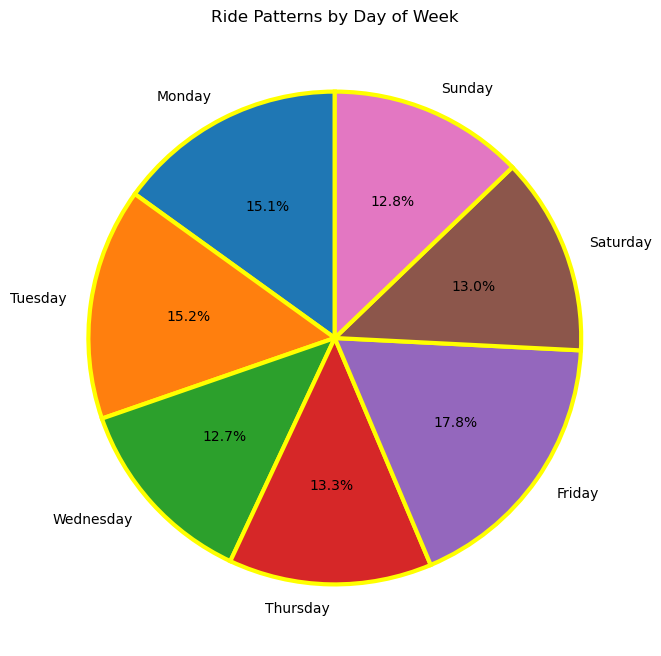

In [363]:
day_count = df["Day_of_Week"].value_counts().reindex(day_order)

plt.figure(figsize=(8,8))
plt.pie(day_count,
        labels=day_count.index,
        autopct='%1.1f%%',
        startangle=90,
        wedgeprops={'edgecolor':'yellow', 'linewidth':3})

plt.title("Ride Patterns by Day of Week")
plt.show()

In [364]:
df["Estimated_Fare"] = df["MILES*"] * 25
fare_trend = df.groupby('Month', observed=True)['Estimated_Fare'].mean().reset_index()
df.head()

,START_DATE*,END_DATE*,Category,Start_Location,Stop_Location,MILES*,PURPOSE,START_DATE,END_DATE,Hour,Day_of_Week,Month,Ride_Duration,Estimated_Fare,Peak_Hour_Count
0,1/1/2016 21:11,1/1/2016 21:17,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain,2016-01-01 21:11:00,2016-01-01 21:17:00,21,Friday,January,6.0,127.5,51
1,1/2/2016 1:25,1/2/2016 1:37,Business,Fort Pierce,Fort Pierce,5.0,Unknown,2016-01-02 01:25:00,2016-01-02 01:37:00,1,Saturday,January,12.0,125.0,5
2,1/2/2016 20:25,1/2/2016 20:38,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies,2016-01-02 20:25:00,2016-01-02 20:38:00,20,Saturday,January,13.0,120.0,71
3,1/5/2016 17:31,1/5/2016 17:45,Business,Fort Pierce,Fort Pierce,4.7,Meeting,2016-01-05 17:31:00,2016-01-05 17:45:00,17,Tuesday,January,14.0,117.5,95
4,1/6/2016 14:42,1/6/2016 15:49,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit,2016-01-06 14:42:00,2016-01-06 15:49:00,14,Wednesday,January,67.0,1592.5,89
